# Ribosome conformation dynamics from full single-molecule traces

This active review uses all 590 author L1–L9 trajectories and all 64281 native valid frames. The two-state global Gaussian HMM is a conditional working model: its reference states are reconstructed latent assignments, not independent molecular truth. Frame duration, distance calibration and an absolute molecular rate are unavailable, so all kinetics remain per frame.

We inspect observations, derive the model, reconstruct freshly, compare state counts, test initialization/decoder conventions, and perturb the observations. The original source's overcounted ELBO diagnostic is unused; 200 fixed posterior updates define the selected validated method.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,observation_sequences
from src.solvers import reconstruct
from src.physics_model import model_log_likelihood,viterbi_sequence
from src.visualization import model_comparison,transition_dwell_frames
from src.main import run
raw,lo,hi=load_observations(ROOT/'data/raw_data.npz');sequences=observation_sequences(raw,lo,hi)
frames=sum(map(len,sequences));assert len(sequences)==590 and frames==64281
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
print('Raw',raw.shape,'valid frames',frames,'all native intervals retained')

Raw (590, 500, 2) valid frames 64281 all native intervals retained


## 1. Observations and their role

The two recorded fluorescence channels form an apparent ratio, $y=I_1/(I_0+I_1)$. Native start/stop annotations identify usable prebleach intervals, not conformational labels. No intensity correction, clipping to [0,1], trace selection or frame subsampling is applied. Ratios above one remain observations and expose the Gaussian model's limitations.

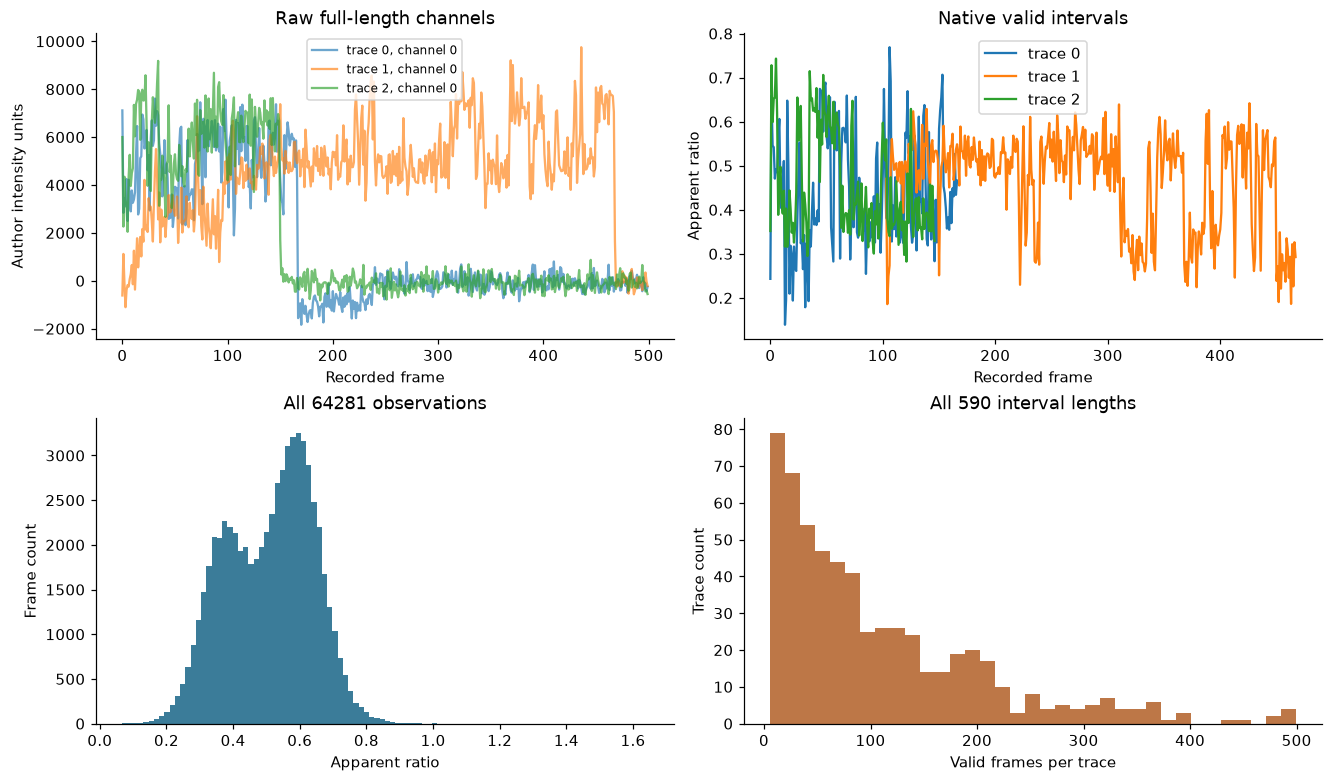

In [2]:
fig,ax=plt.subplots(2,2,figsize=(12,7),layout='constrained')
for i in range(3):
 ax[0,0].plot(raw[i,:,0],alpha=.65,label=f'trace {i}, channel 0')
ax[0,0].set(xlabel='Recorded frame',ylabel='Author intensity units',title='Raw full-length channels');ax[0,0].legend(fontsize=8)
for i in range(3):ax[0,1].plot(np.arange(lo[i],hi[i]),sequences[i],label=f'trace {i}')
ax[0,1].set(xlabel='Recorded frame',ylabel='Apparent ratio',title='Native valid intervals');ax[0,1].legend()
ax[1,0].hist(np.concatenate(sequences),bins=100,color='#3b7c99');ax[1,0].set(xlabel='Apparent ratio',ylabel='Frame count',title='All 64281 observations')
ax[1,1].hist(hi-lo,bins=35,color='#bd7747');ax[1,1].set(xlabel='Valid frames per trace',ylabel='Trace count',title='All 590 interval lengths');plt.show()

## 2. Forward model and shared posterior updates

For trajectory $n$, latent state $z_{nt}$ has start distribution $\pi$ and transition matrix $A$, shared across independent trajectories. Conditional observations obey $y_{nt}\mid z_{nt}=k\sim\mathcal N(\mu_k,\lambda_k^{-1})$. No transition crosses a trajectory boundary.

With Normal–Gamma priors, the expected emission factor is
$$B_{ntk}=\exp\left[\tfrac12\{\psi(a_k)-\log b_k-\log(2\pi)-\beta_k^{-1}-(a_k/b_k)(y_{nt}-m_k)^2\}\right].$$
Here $m,\beta,a,b$ are posterior mean, mean precision factor, precision shape and rate; $\psi$ is digamma. Scaled forward/backward recursion yields state probabilities $r$ and adjacent-pair probabilities $\xi$. Each shared prior is counted once:
$$\alpha_{ij}=1+\sum_{n,t<T_n}\xi_{ntij},\qquad c_i=1+\sum_n r_{n1i}.$$
The output transition matrix normalizes rows of $\alpha$; the start distribution normalizes $c$. Emission variance is $\exp[-\mathbb E\log\lambda]$. Complete Normal–Gamma updates and initialization conventions are in the maintainer approach plan.

In [3]:
started=time.perf_counter();fresh=run();seconds=time.perf_counter()-started
from importlib.util import spec_from_file_location,module_from_spec
spec=spec_from_file_location('review_judge',ROOT/'evaluation/judge.py');judge=module_from_spec(spec);spec.loader.exec_module(judge)
report,status=judge.evaluate(ROOT/'output/reconstruction.npz');assert status==0,report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2))
upstream={k:v.copy() for k,v in np.load(ROOT/'notebooks/reference_outputs/upstream_2_states.npz').items()}
print('Fresh complete fit seconds',seconds);print(json.dumps(report['metrics'],indent=2))
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh_cleaned_2_states.npz',**{k:fresh[k][None] for k in judge.SHAPES})

Fresh complete fit seconds 29.545265199965797
{
  "path_agreement": 1.0,
  "mean_max_abs": 3.3306690738754696e-16,
  "variance_max_abs": 1.0408340855860843e-17,
  "transition_max_abs": 1.1796119636642288e-16,
  "initial_max_abs": 1.1102230246251565e-16,
  "population_max_abs": 2.220446049250313e-16,
  "observation_loglikelihood_per_frame": 1.0067946856737888,
  "decoder_agreement": 1.0
}


## 3. Fresh reconstruction, source comparison and residuals

States use one ensemble-wide increasing-mean convention. State paths and every emission, start, transition and occupancy quantity are compared with an independently captured original run. Residuals subtract the state-dependent conditional mean; their structure is a model diagnostic, not a calibrated measurement-noise estimate. The shaded Gaussian components are conditional distributions, not ground truth.

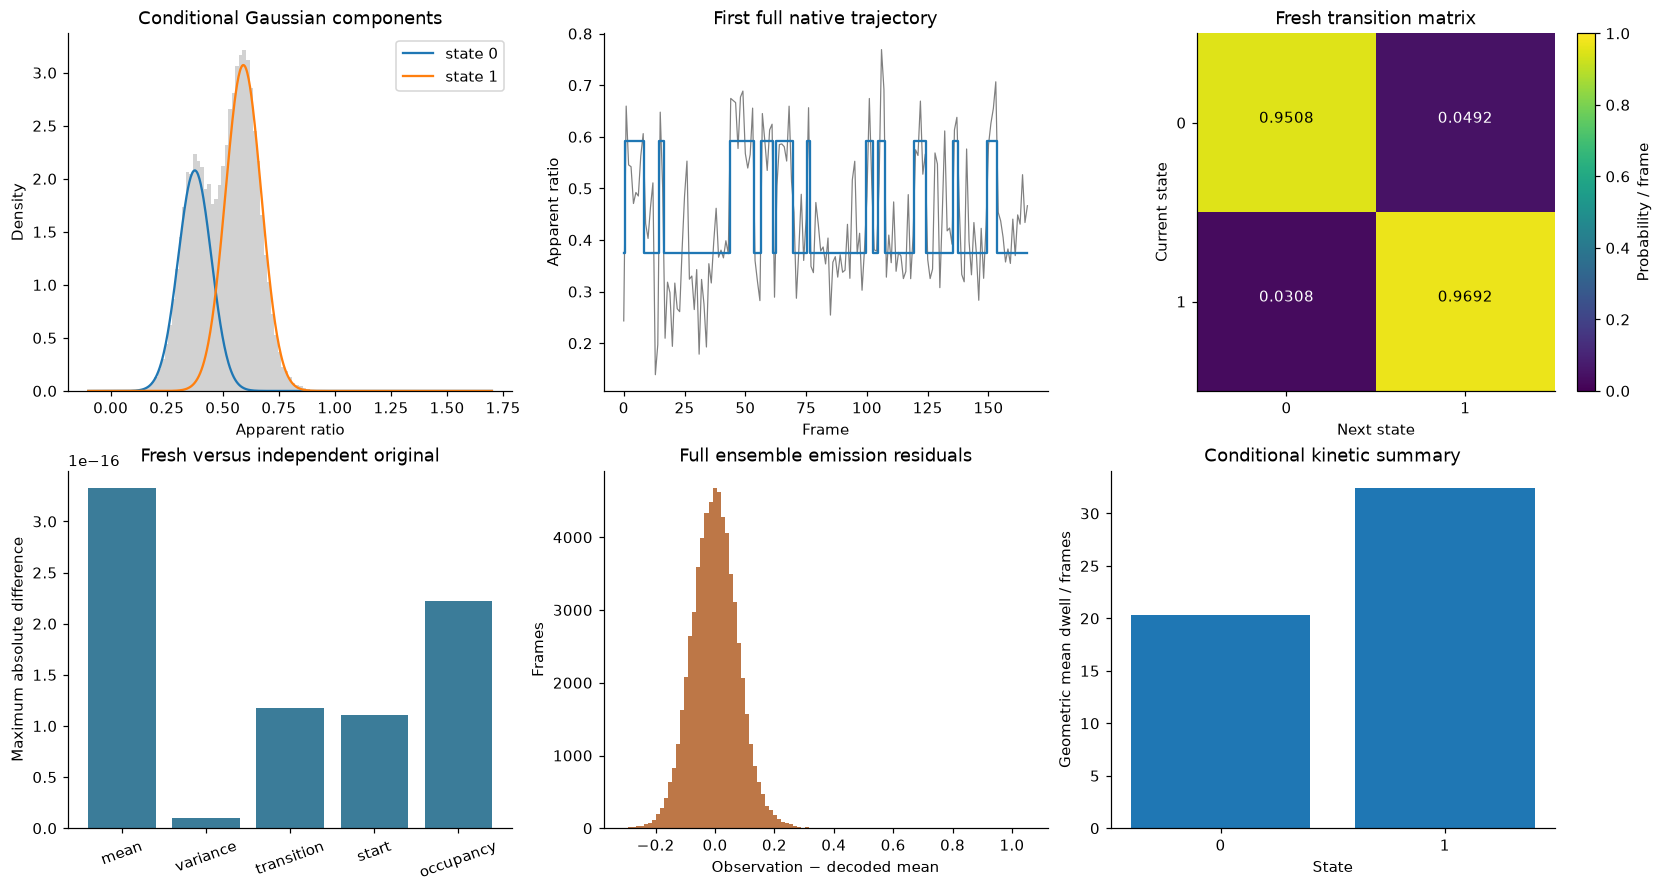

In [4]:
from scipy.stats import norm
fig,ax=plt.subplots(2,3,figsize=(15,8),layout='constrained');grid=np.linspace(-.1,1.7,600)
ax[0,0].hist(np.concatenate(sequences),bins=100,density=True,alpha=.35,color='gray')
for k in range(2):ax[0,0].plot(grid,fresh['population_fraction'][k]*norm.pdf(grid,fresh['state_mean'][k],np.sqrt(fresh['state_variance'][k])),label=f'state {k}')
ax[0,0].set(xlabel='Apparent ratio',ylabel='Density',title='Conditional Gaussian components');ax[0,0].legend()
i=0;axis=np.arange(lo[i],hi[i]);path=fresh['reconstruction'][i,lo[i]:hi[i]]
ax[0,1].plot(axis,sequences[i],color='gray',lw=.8);ax[0,1].step(axis,fresh['state_mean'][path],where='mid');ax[0,1].set(xlabel='Frame',ylabel='Apparent ratio',title='First full native trajectory')
im=ax[0,2].imshow(fresh['transition_probability'],vmin=0,vmax=1,cmap='viridis');fig.colorbar(im,ax=ax[0,2],label='Probability / frame');ax[0,2].set(xlabel='Next state',ylabel='Current state',title='Fresh transition matrix',xticks=[0,1],yticks=[0,1])
for k in range(2):
 for j in range(2):
  value=fresh['transition_probability'][k,j]
  ax[0,2].text(j,k,f"{value:.4f}",ha='center',color='black' if value>.5 else 'white')
keys=['state_mean','state_variance','transition_probability','initial_probability','population_fraction'];errors=[np.max(abs(fresh[k]-upstream[k][0])) for k in keys]
ax[1,0].bar(range(5),errors,color='#3b7c99');ax[1,0].set_xticks(range(5),['mean','variance','transition','start','occupancy'],rotation=20);ax[1,0].set(ylabel='Maximum absolute difference',title='Fresh versus independent original')
valid=fresh['reconstruction']>=0;paths=fresh['reconstruction'][valid];residual=np.concatenate(sequences)-fresh['state_mean'][paths]
ax[1,1].hist(residual,bins=100,color='#bd7747');ax[1,1].set(xlabel='Observation − decoded mean',ylabel='Frames',title='Full ensemble emission residuals')
ax[1,2].bar([0,1],transition_dwell_frames(fresh['transition_probability']));ax[1,2].set(xticks=[0,1],xlabel='State',ylabel='Geometric mean dwell / frames',title='Conditional kinetic summary');plt.show()

## 4. State-count comparison: the working model is imperfect

The one-, two- and three-state fits below are all computed freshly on the entire acquisition with the same 200-update method. We report normalized plug-in likelihood and a BIC-style descriptive score, $-2\ell+d\log N$, where $d=2K+(K-1)+K(K-1)$ counts Gaussian and stochastic-matrix degrees of freedom and $N$ is frame count. This is not a variational ELBO or an exact model evidence. Better three-state prediction is retained rather than used to claim two uniquely identifiable biological conformations.

Fresh 1 states seconds 13.146492800035048


Fresh 3 states seconds 36.84291939996183


[
  {
    "log_likelihood_per_frame": 0.6149124305156647,
    "parameter_count": 2,
    "bic_style_plugin_score": -79032.22985320154,
    "states": 1
  },
  {
    "log_likelihood_per_frame": 1.0067946856737804,
    "parameter_count": 7,
    "bic_style_plugin_score": -129358.04124395586,
    "states": 2
  },
  {
    "log_likelihood_per_frame": 1.062262164165333,
    "parameter_count": 14,
    "bic_style_plugin_score": -136411.55407815016,
    "states": 3
  }
]


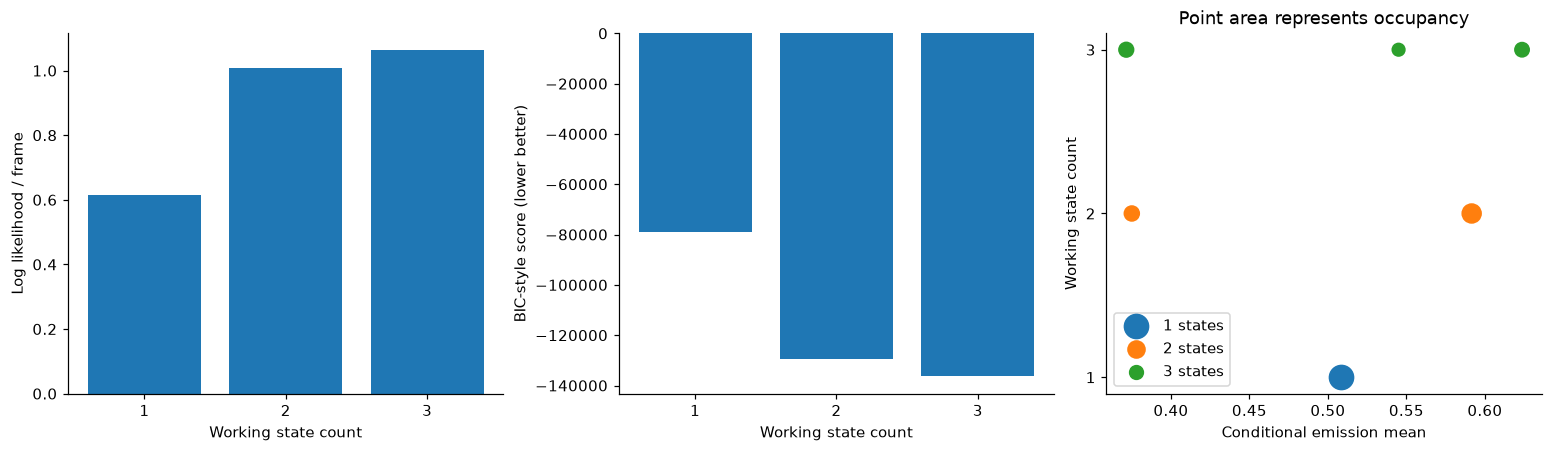

In [5]:
fits={2:fresh};comparison=[]
for k in [1,3]:
 start=time.perf_counter();fits[k]=reconstruct(sequences,states=k);print('Fresh',k,'states seconds',time.perf_counter()-start)
for k in [1,2,3]:
 f=fits[k];ell=model_log_likelihood(sequences,f['state_mean'],f['state_variance'],f['transition_probability'],f['initial_probability']);row=model_comparison(ell,frames,k);row['states']=k;comparison.append(row)
print(json.dumps(comparison,indent=2))
fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained')
ax[0].bar([r['states'] for r in comparison],[r['log_likelihood_per_frame'] for r in comparison]);ax[0].set(xlabel='Working state count',ylabel='Log likelihood / frame',xticks=[1,2,3])
ax[1].bar([r['states'] for r in comparison],[r['bic_style_plugin_score'] for r in comparison]);ax[1].set(xlabel='Working state count',ylabel='BIC-style score (lower better)',xticks=[1,2,3])
for k in [1,2,3]:ax[2].scatter(fits[k]['state_mean'],np.full(k,k),s=250*fits[k]['population_fraction'],label=f'{k} states')
ax[2].set(xlabel='Conditional emission mean',ylabel='Working state count',yticks=[1,2,3],title='Point area represents occupancy');ax[2].legend();plt.show()

## 5. Initialization and decoding ablations

The source GUI decodes using overall frame occupancy as its start distribution. The selected public numerical-core binding instead uses the learned sequence-start distribution; these represent different HMM initial conditions. We retain both as a scientific comparison. A fresh independent random initialization tests the fitted fixed point, and a 100-update fit tests the predeclared iteration choice. Neither uses archived fitted parameters as a start.

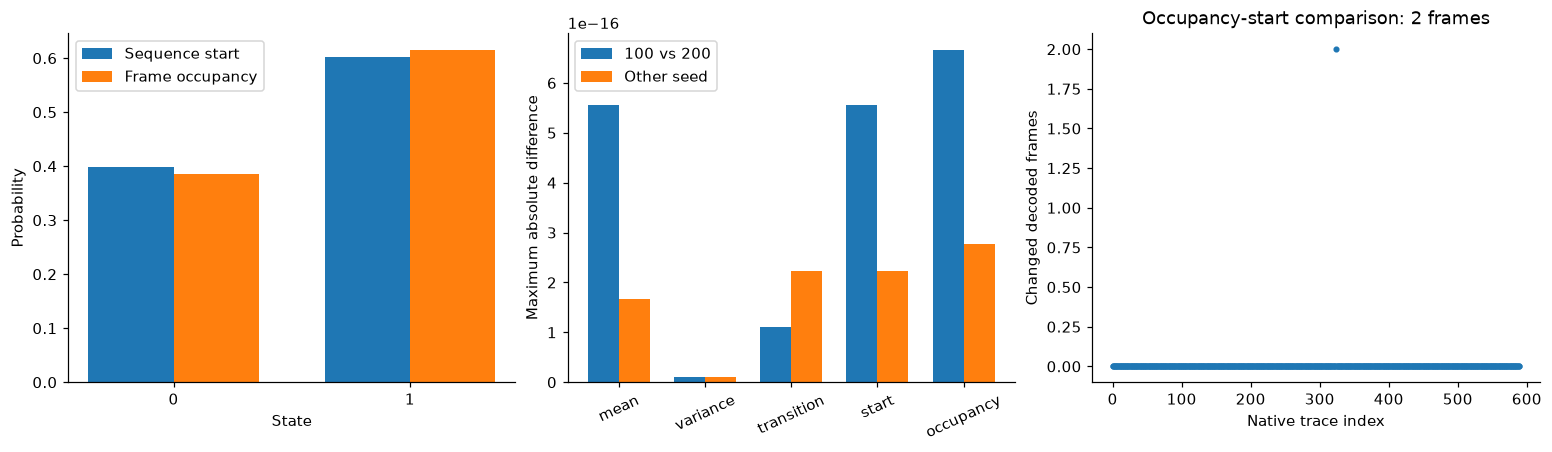

In [6]:
alternative=reconstruct(sequences,seed=20261027);half=reconstruct(sequences,updates=100)
gui_paths=[viterbi_sequence(x,fresh['state_mean'],fresh['state_variance'],fresh['transition_probability'],fresh['population_fraction']) for x in sequences]
core_paths=np.concatenate([fresh['reconstruction'][i,a:b] for i,(a,b) in enumerate(zip(lo,hi))]);gui_flat=np.concatenate(gui_paths)
source_gui=np.load(ROOT/'notebooks/reference_outputs/upstream_gui_population_decoder.npz')['reconstruction'][0][valid]
assert np.array_equal(gui_flat,source_gui)
fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained')
ax[0].bar(np.arange(2)-.18,fresh['initial_probability'],.36,label='Sequence start');ax[0].bar(np.arange(2)+.18,fresh['population_fraction'],.36,label='Frame occupancy');ax[0].set(xticks=[0,1],xlabel='State',ylabel='Probability');ax[0].legend()
diff=[np.max(abs(half[k]-fresh[k])) for k in keys];diff2=[np.max(abs(alternative[k]-fresh[k])) for k in keys]
ax[1].bar(np.arange(5)-.18,diff,.36,label='100 vs 200');ax[1].bar(np.arange(5)+.18,diff2,.36,label='Other seed');ax[1].set_xticks(range(5),['mean','variance','transition','start','occupancy'],rotation=25);ax[1].set(ylabel='Maximum absolute difference');ax[1].legend()
per_trace=np.array([np.count_nonzero(a!=fresh['reconstruction'][i,lo[i]:hi[i]]) for i,a in enumerate(gui_paths)])
ax[2].plot(np.arange(590),per_trace,'.');ax[2].set(xlabel='Native trace index',ylabel='Changed decoded frames',title=f'Occupancy-start comparison: {np.sum(per_trace)} frames');plt.show()

## 6. Observation perturbation and limits

Independent additive apparent-ratio perturbations are a numerical stress test, not a claim about photon statistics or confidence coverage. Every perturbation refits all 590 traces and retains every native frame. Changes are measured relative to the fresh unperturbed working-model estimate. Three-state improvement and heterogeneous trajectories limit biological interpretation even when source parity is exact.

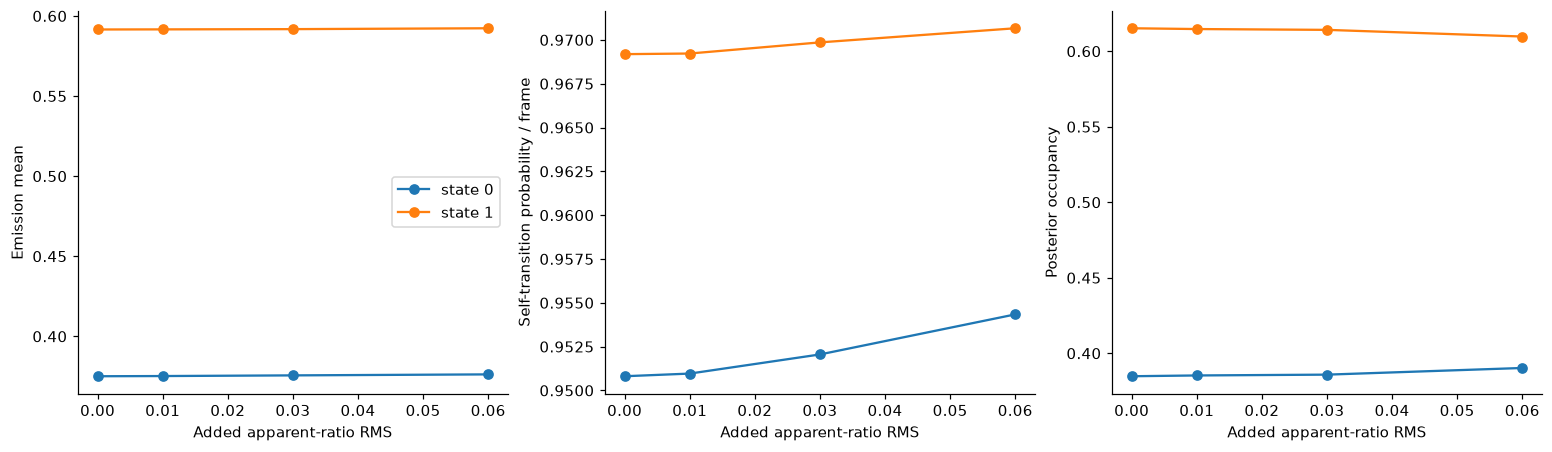

All six required quantities passed the independent evaluator; references are method outputs, not truth.


In [7]:
rng=np.random.default_rng(20261026);stress=[]
for scale in [.01,.03,.06]:
 noisy=[x+rng.normal(0,scale,len(x)) for x in sequences];f=reconstruct(noisy);stress.append({'scale':scale,'mean':f['state_mean'].tolist(),'transition':f['transition_probability'].tolist(),'population':f['population_fraction'].tolist()})
fig,ax=plt.subplots(1,3,figsize=(14,4),layout='constrained');scales=[0]+[r['scale'] for r in stress]
for k in range(2):
 ax[0].plot(scales,[fresh['state_mean'][k]]+[r['mean'][k] for r in stress],'-o',label=f'state {k}')
 ax[1].plot(scales,[fresh['transition_probability'][k,k]]+[r['transition'][k][k] for r in stress],'-o')
 ax[2].plot(scales,[fresh['population_fraction'][k]]+[r['population'][k] for r in stress],'-o')
for a in ax:a.set_xlabel('Added apparent-ratio RMS')
ax[0].set_ylabel('Emission mean');ax[0].legend();ax[1].set_ylabel('Self-transition probability / frame');ax[2].set_ylabel('Posterior occupancy');plt.show()
summary=dict(fresh_runtime_seconds=seconds,frames=frames,traces=len(sequences),judge=report,model_comparison=comparison,decoder_changed_frames=int(np.count_nonzero(core_paths!=gui_flat)),stress=stress)
(ROOT/'notebooks/reference_outputs/fresh_review_measurements.json').write_text(json.dumps(summary,indent=2))
print('All six required quantities passed the independent evaluator; references are method outputs, not truth.')

## Conclusion

The cleaned shared-posterior inference recovers the original two-state method result on the complete author acquisition, including every state path and parameter array. Sequence boundaries, state permutations and the decoder start convention are explicit. The three-state comparison predicts the observations better; these benchmark outputs describe a conditional two-state analysis, not established unique molecular states or absolute physical rates.

References: Verma et al., *Biophysical Journal* (2024), [doi:10.1016/j.bpj.2024.01.022](https://doi.org/10.1016/j.bpj.2024.01.022). Exact source and dataset provenance are recorded in `test/validation.md`.